# Análisis de la Anomalía del Nivel del Mar (SLA) en el Pacífico de Guatemala

**Curso:** Optimización de la gestión de ecosistemas marinos y recursos pesqueros en Latinoamérica mediante ciencia abierta.
**Alumno** Victor José Gómez Ovalle
**Objetivos de la tarea:**
1. Desarrollar un notebook que explique el uso de funciones y creación de graficos utilizando el lenguaje de programación de Phyton.

## Contexto

La **anomalía del nivel del mar** (SLA, conocido como *Sea Level Anomaly*, por sus siglas en ingles) es la diferencia entre la altura de la superficie del mar observada (generalmente por altimetría satelital) y su valor medio de referencia. Valores positivos indican que el mar está más alto de lo normal; valores negativos, más bajo. Estos datos son proporcionados por el programa de la NOAA, CoastWatch, por otro lado, cabe resaltar que en el Pacífico de Guatemala la SLA responde a mareas de tormenta, ondas costeras y, de forma notable, al fenómeno **El Niño / La Niña**.

Se cuenta con series diarias de SLA (en metros) para 8 puntos de la costa del Pacífico guatemalteco, ordenados de oeste a este:

| No. | Departamento | Sitio | Abrev. | Latitud | Longitud |
|---|---|---|---|---|---|
| 1 | San Marcos | Ocós | ocs | 14.50 | -92.20 |
| 2 | Retalhuleu | Champerico | chp | 14.26 | -91.89 |
| 3 | Suchitepéquez | Tahuexco | thx | 14.07 | -91.65 |
| 4 | Escuintla | Tecojate | tcj | 13.97 | -91.36 |
| 5 | Escuintla | Sipacate | spc | 13.92 | -91.15 |
| 6 | Escuintla | Puerto San José | psj | 13.90 | -90.80 |
| 7 | Santa Rosa | Monterrico | mtr | 13.88 | -90.50 |
| 8 | Santa Rosa | Las Lisas | lls | 13.79 | -90.27 |

## 1. Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from pathlib import Path

#Parametros para el mapa de ubicación

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 2. Metadatos de las estaciones

Vamos a guardar la tabla que anteriormente se describe en un formato `DataFrame` para poder generar un mapa de ubicación del mismo

In [3]:
estaciones = pd.DataFrame({
    "codigo":       ["OCS", "CHP", "THX", "TCJ", "SPC", "PSJ", "MTR", "LLS"],
    "sitio":        ["Ocós", "Champerico", "Tahuexco", "Tecojate", "Sipacate",
                     "Puerto San José", "Monterrico", "Las Lisas"],
    "departamento": ["San Marcos", "Retalhuleu", "Suchitepéquez", "Escuintla",
                     "Escuintla", "Escuintla", "Santa Rosa", "Santa Rosa"],
    "lat":          [14.50, 14.26, 14.07, 13.97, 13.92, 13.90, 13.88, 13.79],
    "lon":          [-92.20, -91.89, -91.65, -91.36, -91.15, -90.80, -90.50, -90.27],
}).set_index("codigo")

#Desplegamos la tabla

estaciones

,sitio,departamento,lat,lon
codigo,,,,
OCS,Ocós,San Marcos,14.50,-92.20
CHP,Champerico,Retalhuleu,14.26,-91.89
THX,Tahuexco,Suchitepéquez,14.07,-91.65
TCJ,Tecojate,Escuintla,13.97,-91.36
SPC,Sipacate,Escuintla,13.92,-91.15
PSJ,Puerto San José,Escuintla,13.90,-90.80
MTR,Monterrico,Santa Rosa,13.88,-90.50
LLS,Las Lisas,Santa Rosa,13.79,-90.27


## 3. Funciones

Vamos a definir funciones sencillas para poder cargar un `.csv` en dado caso se nos proporcione algún otro conjuto de datos por ejemplo el Mar Caribe, por otro lado vamos a generar una función para hacer graficos de tendencia para saber cual es la tendencia de cada sitio observado

In [5]:
def cargar_sla(ruta):
    """Lee el CSV de SLA y devuelve un DataFrame con índice de fechas."""
    df = pd.read_csv(ruta)
    df["FECHA"] = pd.to_datetime(df["FECHA"], dayfirst=True)   # convertimos a formato dd/mm/aaaa
    df = df.set_index("FECHA").sort_index()
    return df


def graficar_estacion(df, codigo, ventana=30, ax=None):
    """Grafica la SLA diaria, la media móvil y la tendencia lineal de una estación.

    
    Devuelve la tendencia en mm/año.
    """
    s = df[codigo].dropna()
    anios = s.index.year + (s.index.dayofyear - 1) / 365.25    # fecha -> año decimal
    a, b = np.polyfit(anios, s.values, 1)                       # recta y = a*x + b
    tendencia = a * 1000                                        # m/año -> mm/año

    if ax is None:
        fig, ax = plt.subplots()
    ax.plot(s.index, s, color="lightsteelblue", lw=0.7, label="SLA diaria")
    ax.plot(s.index, s.rolling(ventana, center=True).mean(), color="navy",
            lw=1.5, label=f"Media móvil {ventana} días")
    ax.plot(s.index, a * anios + b, color="crimson", ls="--", lw=1.8,
            label=f"Tendencia: {tendencia:.1f} mm/año")
    ax.axhline(0, color="black", lw=0.7)
    ax.set_title(f"{estaciones.loc[codigo, 'sitio']} ({codigo})")
    ax.set_ylabel("SLA (m)")
    ax.legend(loc="upper left", fontsize=8)
    return tendencia

## 4. Carga y revisión de los datos

Vamos a hacer una pequeña exploración de los datos para ver que nuestras funciones esten activas

In [6]:
sla = cargar_sla("sla_pacifico.csv")

print("Periodo:", sla.index.min().date(), "a", sla.index.max().date())
print("Número de registros:", len(sla))
print("Datos faltantes por estación:")
print(sla.isna().sum())
sla.head()

Periodo: 2019-03-17 a 2026-11-08
Número de registros: 2647
Datos faltantes por estación:
OCS    1
CHP    1
THX    1
TCJ    1
SPC    1
PSJ    1
MTR    1
LLS    1
dtype: int64


,OCS,CHP,THX,TCJ,SPC,PSJ,MTR,LLS
FECHA,,,,,,,,
2019-03-17,0.0290,0.0274,0.0141,0.0006,-0.0157,-0.0261,-0.0209,-0.0220
2019-03-19,0.0318,0.0301,0.0235,0.0203,0.0093,-0.0066,-0.0064,-0.0073
2019-03-20,0.0219,0.0346,0.0232,0.0231,0.0138,0.0167,0.0135,0.0086
2019-03-21,0.0290,0.0342,0.0273,0.0280,0.0192,0.0199,0.0203,0.0163
2019-03-22,0.0338,0.0431,0.0331,0.0365,0.0293,0.0314,0.0247,0.0202


## 5. Gráfico 1 – Ubicación de los puntos de análisis

Graficamos un pequeño mapa de ubicación para saber donde estan los puntos ubicados, para ello se usa un archivo .geojson con el fin de poder tener un contexto del área de análisis

In [9]:
paises = gpd.read_file("centroamerica.geojson")

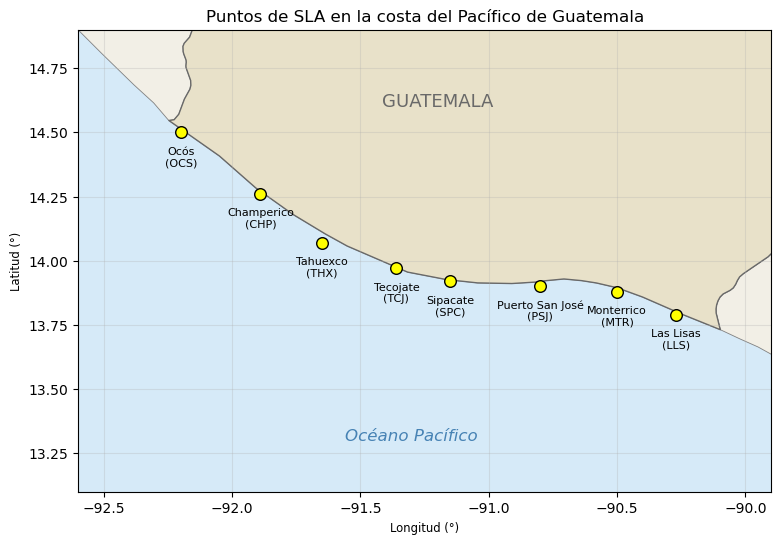

In [11]:
ig, ax = plt.subplots(figsize=(12, 6))
ax.set_facecolor("#d6eaf8")                                   # color del mar
paises.plot(ax=ax, color="#f2efe6", edgecolor="gray", lw=0.6)  # tierra
paises[paises["ADMIN"] == "Guatemala"].plot(ax=ax, color="#e8e1c9",
                                            edgecolor="dimgray", lw=1)

ax.scatter(estaciones["lon"], estaciones["lat"], s=70, color="yellow",
           edgecolor="black", zorder=3)
for cod, fila in estaciones.iterrows():
    ax.annotate(f"{fila['sitio']}\n({cod})", (fila["lon"], fila["lat"]),
                textcoords="offset points", xytext=(0, -24), ha="center", fontsize=8)

ax.text(-91.2, 14.6, "GUATEMALA", fontsize=13, color="dimgray", ha="center")
ax.text(-91.3, 13.3, "Océano Pacífico", fontsize=12, color="steelblue",
        ha="center", style="italic")
ax.set_xlim(-92.6, -89.9)
ax.set_ylim(13.1, 14.9)
ax.set_aspect("equal")
ax.set_title("Puntos de SLA en la costa del Pacífico de Guatemala")
ax.set_xlabel("Longitud (°)")
ax.set_ylabel("Latitud (°)")
plt.show()

## 6. Gráfico 2 – Series de tiempo de todas las estaciones
con el fin de evitar las graficas con picos atipicos se usa una media móvil de 30 días para suavizar la variabilidad diaria.

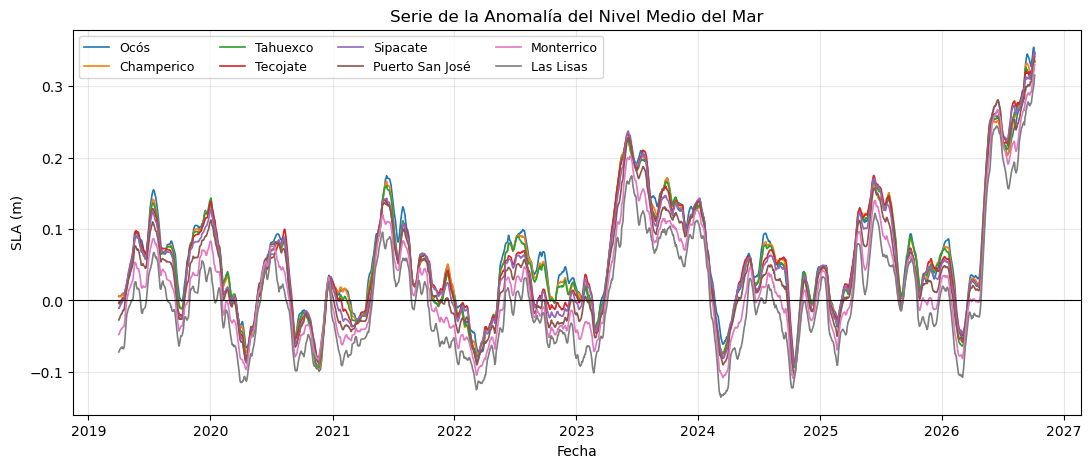

In [13]:
fig, ax = plt.subplots(figsize=(13, 5))
for cod in sla.columns:
    ax.plot(sla.index, sla[cod].rolling(30, center=True).mean(),
            lw=1.2, label=estaciones.loc[cod, "sitio"])
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Serie de la Anomalía del Nivel Medio del Mar")
ax.set_xlabel("Fecha")
ax.set_ylabel("SLA (m)")
ax.legend(ncol=4, fontsize=9)
plt.show()

## 7. Gráfico 3 – Serie y tendencia por estación

Haciendo uso de la función que definimos anteriormente `graficar_estacion` vamos a reutilizar el codigo para poder calcular la tendencia para cada una de las estaciones para el uso de esta función unicamente necesitamos hacer uso de la tabla de datos e ingresar el codigo de cada sitio de monitoreo, por otro lado vamos a usar un for para generar un ciclo para cada sitio de monitoreo disponible

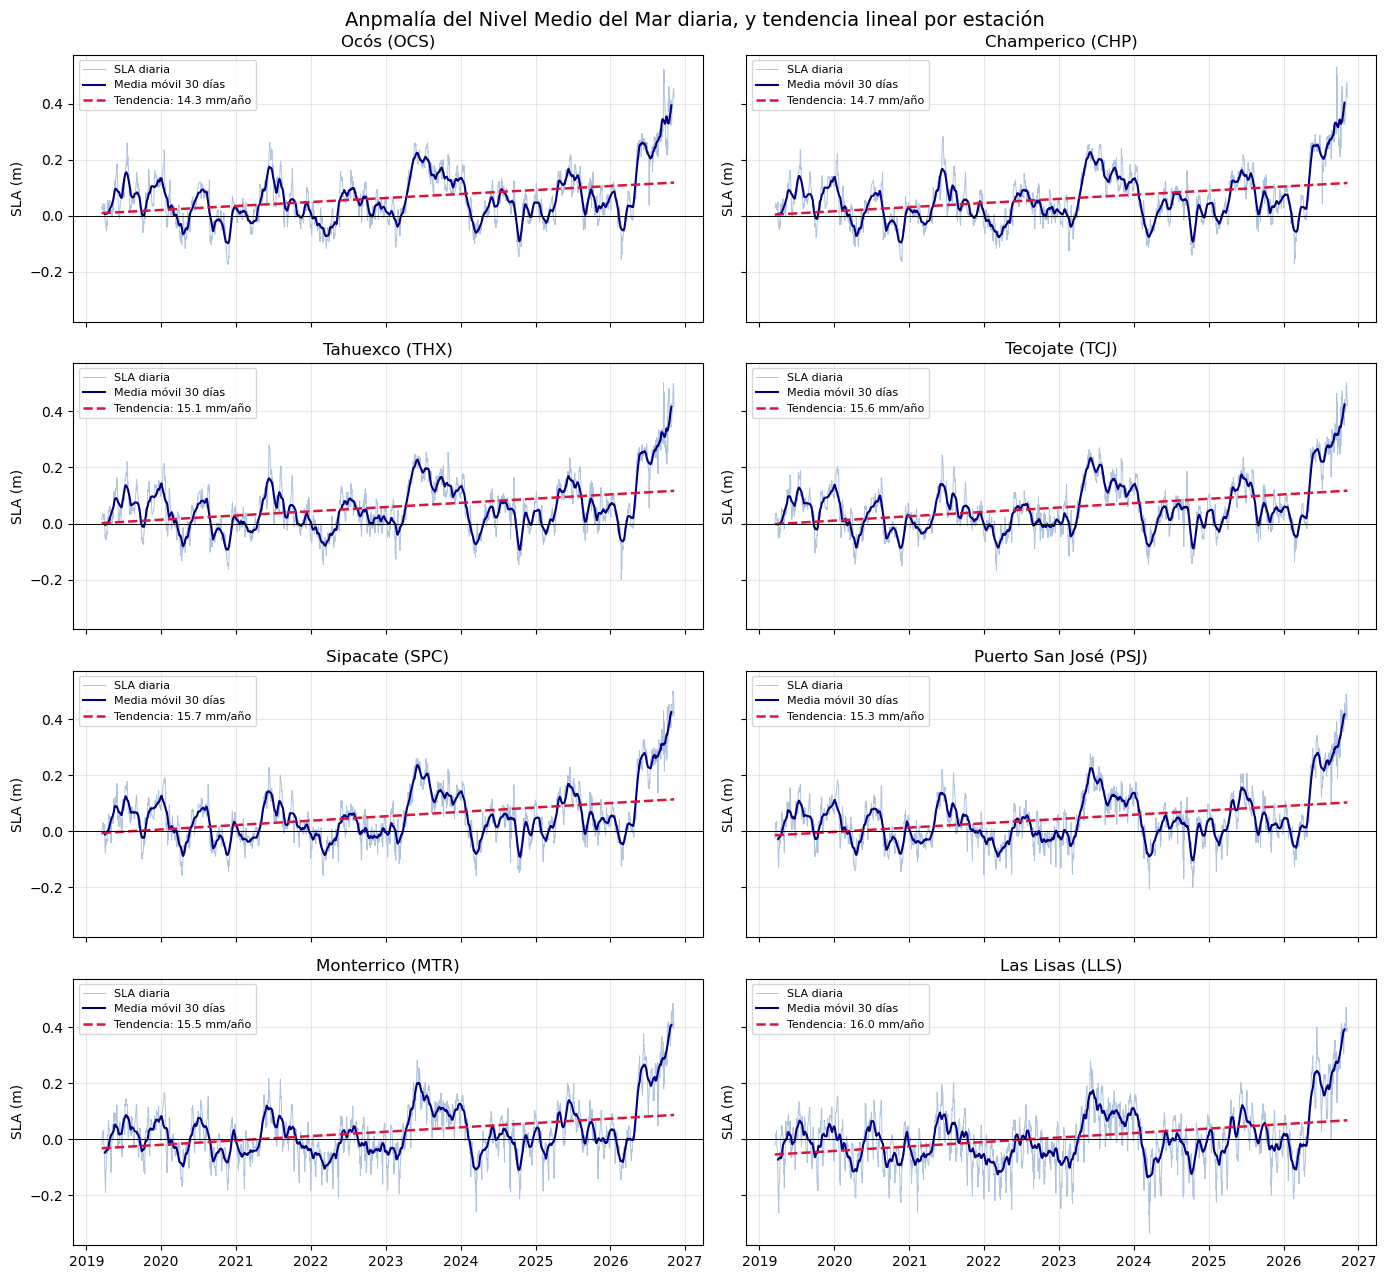

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(14, 13), sharex=True, sharey=True)
for ax, cod in zip(axes.flat, sla.columns):
    graficar_estacion(sla, cod, ventana=30, ax=ax)
fig.suptitle("Anpmalía del Nivel Medio del Mar diaria, y tendencia lineal por estación", fontsize=14)
plt.tight_layout()
plt.show()

## 8. Conclusiones

- Las 8 estaciones muestran un comportamiento muy similar en el tiempo (las curvas casi se superponen), lo cual es esperable porque están a lo largo de la misma franja costera.
- Hay un gradiente oeste → este en el valor medio: Ocós tiene una SLA media de ~6.4 cm y Las Lisas de ~0.8 cm.
- Las líneas de tendencia son positivas en todas las estaciones (~14–16 mm/año en 2019–2026).
- Los valores más altos se presentan en 2023 y 2026, en condiciones de El Niño, y los más bajos en 2020 y 2022, con La Niña.